# Supplementary figure: gene sets along the ranking (without the cell-type signatures)

The cell-type signatures are in Figure 6b (`fig6_tss_interpretation.ipynb`); this figure shows the other gene sets.

| panel | what is drawn | source data (`data/no_deep/`) |
|---|---|---|
| a, b | running enrichment score of the promoter genes of Zhu et al. along the ranking, with the hits, the ranked list and Cohen's *d* | `figS18_zhu_es_curves.csv`, `figS18_zhu_es_summary.csv`, `figS18_tss_sets.csv` |
| c | Hallmark sets enriched against matched random sets of TSSs (q < 0.05 in at least one task) | `figS18_gsea_matched_10k.csv` |
| d | Reactome pathways, same test | `figS18_gsea_matched_10k.csv` |

Exporters: `export/export_figS18_gene_sets.py`, `export/export_figS18_matched_10k.py`, `export/export_figS18_zhu_es.py`. Output: `output/no_deep/figS_gene_sets.png` (600 dpi) and `.pdf`.

In [1]:
import os, json

# Data paths are relative to src/figures/; hop there if the kernel started elsewhere
if not os.path.isdir("data") and os.path.isdir(os.path.join("src", "figures", "data")):
    os.chdir(os.path.join("src", "figures"))

# --- cohort switch ------------------------------------------------------------------
COHORT = os.environ.get("FIG_COHORT", "no_deep")   # no_deep is the default cohort
assert COHORT in ("all", "no_deep"), COHORT
_DATA = "data" if COHORT == "all" else os.path.join("data", COHORT)
_OUT = "output" if COHORT == "all" else os.path.join("output", COHORT)
os.makedirs(_OUT, exist_ok=True)


def data_path(name):
    p = os.path.join(_DATA, name)
    assert os.path.exists(p), f"{p} missing - run COHORT_VARIANT={COHORT} python export/export_figS18_gene_sets.py"
    return p


def out_path(name):
    return os.path.join(_OUT, name)


print(f"cohort: {COHORT} (source data from {_DATA}/, figures to {_OUT}/)")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

TASKS = ["brca_crc", "pancan"]
TASK_LABELS = {"brca_crc": "BRCA/CRC versus healthy", "pancan": "Pan-cancer versus healthy"}
import _figstyle as fs          # the shared figure style of the manuscript (180 mm wide, 7 pt)
fs.apply()
TASK_COLORS = {t: fs.TASK[TASK_LABELS[t]] for t in TASKS}

cohort: no_deep (source data from data\no_deep/, figures to output\no_deep/)


In [2]:
COUNTS = {}
# ---- helpers (as in figS18_gene_sets.ipynb, without its cell-type panel) ----
LA = pd.read_csv(data_path("figS18_gsea_matched_10k.csv"))
assert int(LA["n_null"].iloc[0]) == 10000 and "reactome" in set(LA["collection"]), "rerun export/export_figS18_matched_10k.py"
LA["sig"] = LA["rank_auc_signed_d_q"] < 0.05
LA["z"] = LA["rank_auc_signed_d_z"]


def la_table(coll):
    """Look-alike results of one collection, wide over the two tasks; only sets with q < 0.05 in >= 1 task."""
    x = LA[LA["collection"] == coll].pivot_table(index="term", columns="contrast", values=["z", "sig", "n_genes_matched"], aggfunc="first")
    keep = x["sig"][TASKS].astype(bool).any(axis=1)
    return x[keep]


SET_NAMES = {   # names as printed in the figure where lower-casing the MSigDB name loses an acronym or a hyphen
    "HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION": "Epithelial–mesenchymal transition",
    "HALLMARK_UV_RESPONSE_DN": "UV response (down)",
    "HALLMARK_INTERFERON_GAMMA_RESPONSE": "Interferon-gamma response",
    "REACTOME_O_GLYCOSYLATION_OF_TSR_DOMAIN_CONTAINING_PROTEINS": "O-glycosylation of TSR domain-containing proteins",
    "REACTOME_RUNX1_REGULATES_TRANSCRIPTION_OF_GENES_INVOLVED_IN_DIFFERENTIATION_OF_HSCS": "RUNX1 regulates genes involved in HSC differentiation",
    "REACTOME_VOLTAGE_GATED_POTASSIUM_CHANNELS": "Voltage-gated potassium channels",
}

def nice(term):
    if term in SET_NAMES:
        return SET_NAMES[term]
    s = term.replace("HALLMARK_", "").replace("REACTOME_", "").replace("_", " ").lower()
    return s[:1].upper() + s[1:]


ZLIM = float(np.ceil(LA.loc[LA["sig"], "z"].abs().max() + 0.5))
XLAB = "Enrichment (z)"
XLAB_LEFT = "← less active\nin cancer\n(shallower dip)"
XLAB_RIGHT = "more active →\nin cancer\n(deeper dip)"
size = lambda n: 2 + np.asarray(n, float) / 8.0     # dot area (pt^2) ~ number of TSSs in the set
DOT_OFFSET = 0.28                                   # vertical offset of the two tasks' dots, in rows
TASK_SHORT = {"brca_crc": "BRCA/CRC", "pancan": "pan-cancer"}


def minus(s):
    """Typographic minus for numbers printed in the figure."""
    return s.replace("-", "−")


def dots(ax, x, y, n, sig, t):
    sig = np.asarray(sig, bool)
    ax.scatter(np.asarray(x)[sig], np.asarray(y)[sig], s=size(np.asarray(n)[sig]), color=TASK_COLORS[t], alpha=0.9, edgecolors="white", linewidths=0.3, zorder=3)
    ax.scatter(np.asarray(x)[~sig], np.asarray(y)[~sig], s=size(np.asarray(n)[~sig]), facecolors="none", edgecolors=TASK_COLORS[t], linewidths=0.7, zorder=3)


def style(ax, letter, title, cnt, n_tot):
    ax.axvline(0, color=fs.NEUTRAL, lw=0.6); ax.set_xlim(-ZLIM, ZLIM); ax.set_xlabel(XLAB)
    ax.annotate(XLAB_LEFT, xy=(0, 0), xycoords="axes fraction", xytext=(0, -27), textcoords="offset points", ha="left", va="top", fontsize=fs.VALUE)
    ax.annotate(XLAB_RIGHT, xy=(1, 0), xycoords="axes fraction", xytext=(0, -27), textcoords="offset points", ha="right", va="top", multialignment="right", fontsize=fs.VALUE)
    fs.value_grid(ax, "x"); ax.tick_params(axis="y", length=0)
    fs.panel(ax, letter, title)


def set_panel(ax, coll, letter, title):
    """Hallmark / Reactome: one row per set that differs from its look-alikes, one dot per task."""
    x = la_table(coll)
    order = x["z"][TASKS].mean(axis=1).sort_values().index
    y = np.arange(len(order))
    for j, t in enumerate(TASKS):
        r = x.reindex(order)
        dots(ax, r["z"][t], y + (j - 0.5) * DOT_OFFSET, r["n_genes_matched"][t], r["sig"][t].astype(bool), t)
    ax.set_yticks(y); ax.set_yticklabels([nice(o) for o in order]); ax.set_ylim(-0.7, len(order) - 0.3)
    n_tot = LA[(LA["collection"] == coll) & (LA["contrast"] == "pancan")].shape[0]
    cnt = {t: int(LA[(LA["collection"] == coll) & (LA["contrast"] == t)]["sig"].sum()) for t in TASKS}
    COUNTS[coll] = (cnt, n_tot)
    style(ax, letter, title, cnt, n_tot)


ZES = pd.read_csv(data_path("figS18_zhu_es_curves.csv"))
ZSUM = pd.read_csv(data_path("figS18_zhu_es_summary.csv")).set_index("contrast")
_tss18 = pd.read_csv(data_path("figS18_tss_sets.csv"), usecols=["in_zhu_promoter", "d_brca_crc", "d_pancan"])


def zhu_panel(axs, t, letter, es_lim, d_lim):
    """Classic GSEA enrichment plot of the Zhu promoter TSSs on four stacked axes: running enrichment score, hits,
    the ranked list as a colour bar, and the ranking metric (d) with its zero cross."""
    ax, axh, axc, axm = axs
    r = ZSUM.loc[t]; x = ZES["rank"].to_numpy(); n_all = len(x)
    d = np.sort(_tss18[f"d_{t}"].fillna(0).to_numpy())[::-1]
    pos = np.empty(n_all, int); pos[np.argsort(-_tss18[f"d_{t}"].fillna(0).to_numpy(), kind="stable")] = np.arange(1, n_all + 1)
    hits = pos[_tss18["in_zhu_promoter"].astype(bool).to_numpy()]
    p = r["p_lookalike"]
    # running enrichment score
    ax.plot(x, ZES[f"{t}_zhu"], color=TASK_COLORS[t], lw=1.1)
    ax.axhline(0, color=fs.NEUTRAL, lw=0.6); ax.set_xlim(1, n_all); ax.set_ylim(*es_lim)
    ax.tick_params(axis="x", bottom=False, labelbottom=False)
    ax.set_ylabel("Enrichment score (ES)")
    ax.text(0.03, 0.04, f"n = {int(r['n_tss'])} TSSs\nES = {minus(format(r['es'], '+.2f'))}, " + (f"p = {p:.4f}" if p < 0.001 else f"p = {p:.3f}"),
            transform=ax.transAxes, ha="left", va="bottom", fontsize=fs.VALUE)
    fs.panel(ax, letter, f"Zhu et al. promoter genes, {TASK_SHORT[t]}")
    # hits
    axh.vlines(hits, 0, 1, color="black", lw=0.3); axh.set_ylim(0, 1); axh.set_yticks([])
    axh.tick_params(axis="x", bottom=False, labelbottom=False); axh.spines["bottom"].set_visible(False)
    # ranked list as a colour bar (red: deeper dip in cancer, blue: shallower)
    lim = np.percentile(np.abs(d), 99)
    axc.imshow(d[None, :], aspect="auto", cmap="RdBu_r", vmin=-lim, vmax=lim, extent=(1, n_all, 0, 1), interpolation="nearest")
    axc.set_yticks([]); axc.tick_params(axis="x", bottom=False, labelbottom=False); axc.spines["bottom"].set_visible(False)
    # ranking metric
    axm.fill_between(np.arange(1, n_all + 1), d, 0, color="0.7", lw=0)
    zc = int((d > 0).sum())
    axm.axvline(zc, color=fs.NEUTRAL, ls="--", lw=0.6, dashes=(3, 2))
    axm.text(zc, d_lim[1] * 0.12, f" zero cross at {zc:,}", fontsize=fs.VALUE, ha="left", va="bottom")
    axm.text(0.01, 0.97, "d > 0: more active in cancer", transform=axm.transAxes, fontsize=fs.VALUE, color="#B2182B", va="top")
    axm.text(0.99, 0.03, "d < 0: less active in cancer", transform=axm.transAxes, fontsize=fs.VALUE, color="#2166AC", ha="right", va="bottom")
    axm.set_ylim(*d_lim); axm.set_ylabel("Cohen's d")
    axm.set_xticks([1, 2500, 5000, 7500, 10000, 12500, n_all])
    axm.set_xticklabels(["1", "2,500", "5,000", "7,500", "10,000", "12,500", f"{n_all:,}"])
    axm.set_xlabel("Rank in the ordered list of TSSs")

saved output\no_deep\figS_gene_sets.png/.pdf at 178 x 183 mm


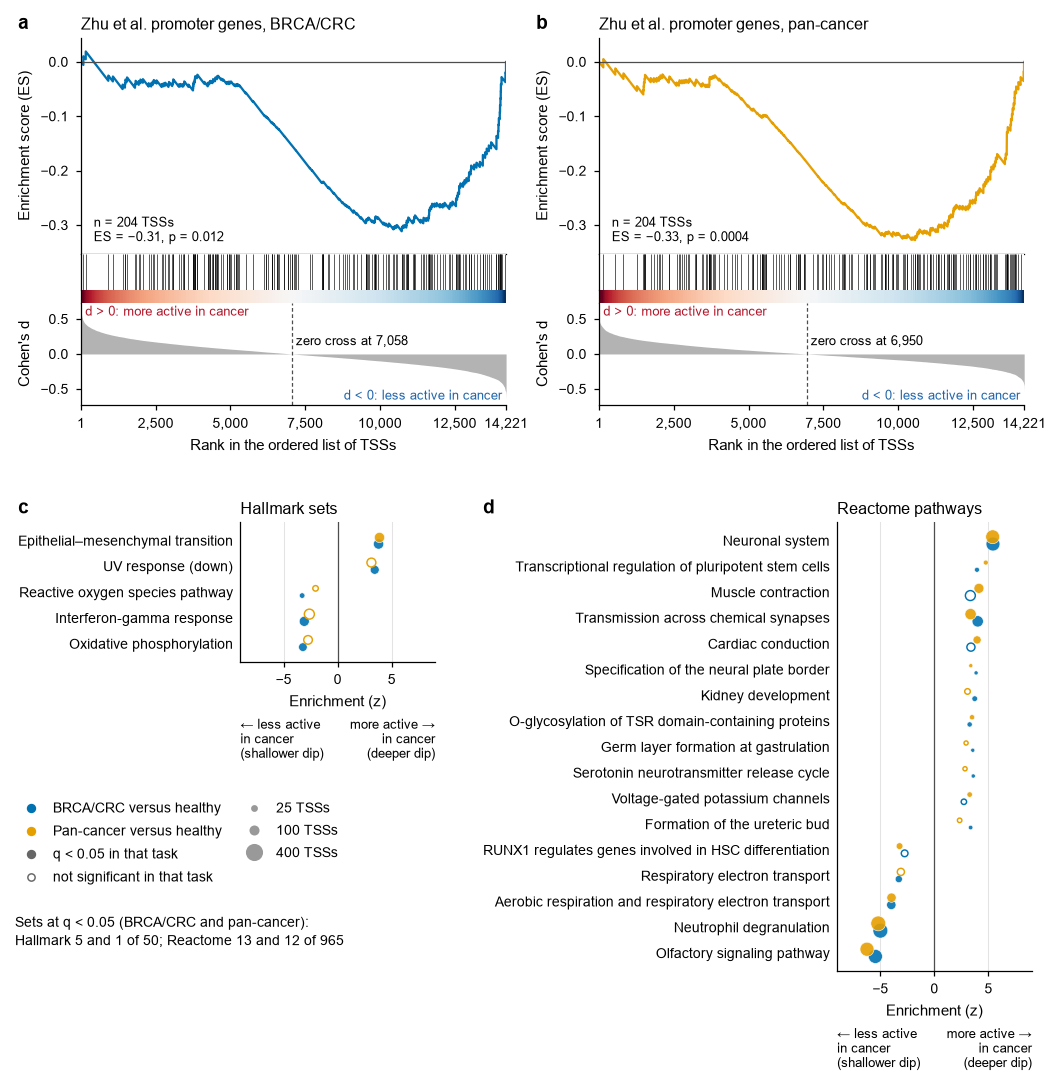

Zhu promoter genes, BRCA/CRC versus healthy: ES = -0.31, p = 0.012 (204 TSSs, 10,000 matched random sets)
Zhu promoter genes, Pan-cancer versus healthy: ES = -0.33, p = 0.0004 (204 TSSs, 10,000 matched random sets)
hallmark: 5 and 1 of 50 sets enriched (q < 0.05)
reactome: 13 and 12 of 965 sets enriched (q < 0.05)
written: output\no_deep\figS_gene_sets.png


In [3]:
# printed size, 180 mm wide; the axes are placed by hand (in inches) because the GSEA plots are stacks of four axes without gaps
W, H = fs.WIDTH, 7.2
figF = plt.figure(figsize=fs.size(height=H))


def box(x0, y0, w, h):
    """Axes rectangle in inches -> figure fraction."""
    return [x0 / W, y0 / H, w / W, h / H]


# --- a, b: running enrichment score of the Zhu promoter genes, one stack of four axes per task -----------------
TOP = H - 0.24                                       # top of the enrichment-score axes (the titles sit above)
STACK = np.array([4.2, 0.7, 0.25, 2.0]); STACK = STACK / STACK.sum() * 2.45     # heights of the four axes, inches
L_AB, GAP_AB, R_AB = 0.52, 0.62, 0.2
W_AB = (W - L_AB - GAP_AB - R_AB) / 2
es_all = ZES[[f"{t}_zhu" for t in TASKS]].to_numpy()
ES_LIM = (es_all.min() - 0.025, es_all.max() + 0.025)            # one scale for a and b
D_MAX = max(_tss18[f"d_{t}"].abs().max() for t in TASKS)
D_LIM = (-1.1 * D_MAX, 1.1 * D_MAX)
for k, (t, letter) in enumerate(zip(TASKS, "ab")):
    axs, y = [], TOP
    for h in STACK:
        y -= h
        axs.append(figF.add_axes(box(L_AB + k * (W_AB + GAP_AB), y, W_AB, h), sharex=axs[0] if axs else None))
    zhu_panel(axs, t, letter, ES_LIM, D_LIM)

# --- c, d: Hallmark and Reactome sets; the same row pitch in both, the tick labels measured to fit ---------------
BOT_TOP, BOT_Y0 = TOP - STACK.sum() - 0.78, 0.74
axC, axD = figF.add_axes(box(1, 1, 1, 1)), figF.add_axes(box(1, 1, 1, 1))
set_panel(axC, "hallmark", "c", "Hallmark sets")
set_panel(axD, "reactome", "d", "Reactome pathways")
figF.canvas.draw()
rend = figF.canvas.get_renderer()
lab = {ax: max(l.get_window_extent(rend).width for l in ax.get_yticklabels()) / figF.dpi + 5 / 72 for ax in (axC, axD)}   # tick-label width + pad, inches
span = {ax: float(np.diff(ax.get_ylim())[0]) for ax in (axC, axD)}                                           # rows
L_C, GAP_CD, R_CD = 0.08, 0.3, 0.15
W_CD = (W - L_C - lab[axC] - GAP_CD - lab[axD] - R_CD) / 2
pitch = (BOT_TOP - BOT_Y0) / span[axD]
x_c = L_C + lab[axC]
axD.set_position(box(x_c + W_CD + GAP_CD + lab[axD], BOT_Y0, W_CD, BOT_TOP - BOT_Y0))
h_c = pitch * span[axC]
axC.set_position(box(x_c, BOT_TOP - h_c, W_CD, h_c))
# legend of c and d below c
LEG_TOP = BOT_TOP - h_c - 0.9
axL = figF.add_axes(box(L_C, LEG_TOP - 0.7, lab[axC] + W_CD, 0.7)); axL.axis("off")
axL.legend(handles=[Line2D([], [], marker="o", ls="none", color=TASK_COLORS[t], label=TASK_LABELS[t]) for t in TASKS]
           + [Line2D([], [], marker="o", ls="none", color="0.4", label="q < 0.05 in that task"),
              Line2D([], [], marker="o", ls="none", markerfacecolor="none", markeredgecolor="0.4", markeredgewidth=0.7, label="not significant in that task")]
           + [Line2D([], [], marker="o", ls="none", color="0.6", markersize=np.sqrt(size(n)), label=f"{n} TSSs") for n in (25, 100, 400)],
           loc="upper left", bbox_to_anchor=(0.0, 1.0), ncol=2, labelspacing=0.7, columnspacing=1.6, borderaxespad=0)
# the number of enriched sets per collection and task (c and d show only the sets with q < 0.05 in at least one task)
axL.text(0.0, -0.12, "Sets at q < 0.05 (BRCA/CRC and pan-cancer):\n" + "; ".join(
    f"{name} {COUNTS[coll][0]['brca_crc']} and {COUNTS[coll][0]['pancan']} of {COUNTS[coll][1]}" for coll, name in [("hallmark", "Hallmark"), ("reactome", "Reactome")]),
    transform=axL.transAxes, ha="left", va="top", fontsize=fs.SMALL, linespacing=1.4)
fs.save(figF, out_path("figS_gene_sets"))
plt.show()

# pinned values
assert COUNTS["hallmark"] == ({"brca_crc": 5, "pancan": 1}, 50), COUNTS["hallmark"]
assert COUNTS["reactome"] == ({"brca_crc": 13, "pancan": 12}, 965), COUNTS["reactome"]
for t, (es, p) in {"brca_crc": ("-0.31", "0.012"), "pancan": ("-0.33", "0.0004")}.items():
    r = ZSUM.loc[t]
    assert f"{r['es']:.2f}" == es and (f"{r['p_lookalike']:.4f}" if r["p_lookalike"] < 0.001 else f"{r['p_lookalike']:.3f}") == p, (t, r["es"], r["p_lookalike"])
    print(f"Zhu promoter genes, {TASK_LABELS[t]}: ES = {r['es']:+.2f}, p = {r['p_lookalike']:.4g} ({int(r['n_tss'])} TSSs, {int(r['n_null']):,} matched random sets)")
for coll, (cnt, n_tot) in COUNTS.items():
    print(f"{coll}: {cnt['brca_crc']} and {cnt['pancan']} of {n_tot} sets enriched (q < 0.05)")
print("written:", out_path("figS_gene_sets.png"))